# Week 6 Day 4 — Global Power Plant Database
### NumPy · Pandas · Matplotlib · Seaborn · Statistical Analysis

**Objective:** Analyze global power plant capacity, fuel types, country distribution, commissioning years, and relationships among numeric variables.

**Important:** `capacity_mw` measures installed capacity, not electricity actually produced. Observational associations do not establish causation. Historical commissioning-year records may be incomplete.

In [1]:
from pathlib import Path
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
SEED = 42
BASE = Path.cwd()
DATA_URL = "https://github.com/devtlv/Datasets-DA-Bootcamp-2-/raw/refs/heads/main/Week%206%20-%20Applications%20for%20Data%20Analysis/W6D2%20-%20Advanced%20Numpy/globalpowerplantdatabasev130.zip"
OUT = BASE / "results"
OUT.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()

print("Output directory:", OUT)

Output directory: C:\Users\Avi\Desktop\Data\DI_Bootcamp\Week6\Day4\DailyChallenge\results


## 1. Import, inspect and clean

In [2]:
# Prefer a local CSV/ZIP if present; otherwise download the assignment ZIP.
local_csvs = list(BASE.glob("global_power_plant_database*.csv")) + list(BASE.glob("globalpowerplantdatabase*.csv"))
local_zips = list(BASE.glob("globalpowerplantdatabase*.zip"))
if local_csvs:
    print("Reading local CSV:", local_csvs[0].name)
    raw = pd.read_csv(local_csvs[0], low_memory=False)
else:
    if local_zips:
        print("Reading local ZIP:", local_zips[0].name)
        content = local_zips[0].read_bytes()
    else:
        print("Downloading source ZIP...")
        try:
            req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=90) as response:
                content = response.read()
        except Exception as exc:
            raise RuntimeError("Download failed. Download the ZIP from the assignment link and place it beside this notebook.") from exc
    with zipfile.ZipFile(io.BytesIO(content)) as z:
        names = [name for name in z.namelist() if name.lower().endswith('.csv') and not name.startswith('__MACOSX')]
        if not names:
            raise ValueError("ZIP contains no CSV. Available files: " + str(z.namelist()[:20]))
        names.sort(key=lambda s: ('global_power_plant_database' not in s.lower(), len(s)))
        print("Reading ZIP member:", names[0])
        with z.open(names[0]) as stream:
            raw = pd.read_csv(stream, low_memory=False)

print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Missing values (top 15):")
display(raw.isna().sum().sort_values(ascending=False).head(15).to_frame('Missing'))
display(raw.head())

Reading ZIP member: global_power_plant_database.csv
Raw shape: (34936, 36)
Columns: ['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw', 'latitude', 'longitude', 'primary_fuel', 'other_fuel1', 'other_fuel2', 'other_fuel3', 'commissioning_year', 'owner', 'source', 'url', 'geolocation_source', 'wepp_id', 'year_of_capacity_data', 'generation_gwh_2013', 'generation_gwh_2014', 'generation_gwh_2015', 'generation_gwh_2016', 'generation_gwh_2017', 'generation_gwh_2018', 'generation_gwh_2019', 'generation_data_source', 'estimated_generation_gwh_2013', 'estimated_generation_gwh_2014', 'estimated_generation_gwh_2015', 'estimated_generation_gwh_2016', 'estimated_generation_gwh_2017', 'estimated_generation_note_2013', 'estimated_generation_note_2014', 'estimated_generation_note_2015', 'estimated_generation_note_2016', 'estimated_generation_note_2017']
Exact duplicate rows: 0
Missing values (top 15):


,Missing
other_fuel3,34844
other_fuel2,34660
other_fuel1,32992
generation_gwh_2013,28519
generation_gwh_2014,27710
generation_gwh_2015,26733
generation_gwh_2016,25792
generation_gwh_2017,25436
generation_gwh_2018,25299
generation_gwh_2019,25277


,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
0,AFG,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,GEODB0040538,33.0,32.322,65.1190,Hydro,NaN,NaN,...,123.77,162.90,97.39,137.76,119.50,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
1,AFG,Afghanistan,Kandahar DOG,WKS0070144,10.0,31.670,65.7950,Solar,NaN,NaN,...,18.43,17.48,18.25,17.70,18.29,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
2,AFG,Afghanistan,Kandahar JOL,WKS0071196,10.0,31.623,65.7920,Solar,NaN,NaN,...,18.64,17.58,19.10,17.62,18.72,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
3,AFG,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,GEODB0040541,66.0,34.556,69.4787,Hydro,NaN,NaN,...,225.06,203.55,146.90,230.18,174.91,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
4,AFG,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,GEODB0040534,100.0,34.641,69.7170,Hydro,NaN,NaN,...,406.16,357.22,270.99,395.38,350.80,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


In [3]:
df = raw.drop_duplicates().copy()
required = ['country', 'primary_fuel', 'capacity_mw']
missing_cols = [col for col in required if col not in df.columns]
if missing_cols:
    raise KeyError(f"Required columns missing: {missing_cols}. Available: {df.columns.tolist()}")
for col in ['capacity_mw', 'commissioning_year', 'latitude', 'longitude', 'generation_gwh_2017']:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors='coerce')
for col in ['country', 'primary_fuel']:
    df[col] = df[col].astype('string').str.strip().replace('', pd.NA)
# Core analysis requires a known country, fuel and nonnegative capacity.
df = df.dropna(subset=required)
df = df.loc[df['capacity_mw'].ge(0)].copy()
if 'commissioning_year' in df:
    df.loc[~df['commissioning_year'].between(1800, 2025), 'commissioning_year'] = np.nan
if 'latitude' in df:
    df.loc[~df['latitude'].between(-90, 90), 'latitude'] = np.nan
if 'longitude' in df:
    df.loc[~df['longitude'].between(-180, 180), 'longitude'] = np.nan
print('Cleaned shape:', df.shape)
print('Remaining missing values (top 15):')
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame('Missing'))
display(df.select_dtypes(include='number').describe().T)
# Missing optional year/coordinates are retained as missing rather than invented.
# A zero or imputed capacity would distort plant and fuel comparisons.
df.to_csv(OUT / 'cleaned_power_plants.csv', index=False)

Cleaned shape: (34936, 36)
Remaining missing values (top 15):


,Missing
other_fuel3,34844
other_fuel2,34660
other_fuel1,32992
generation_gwh_2013,28519
generation_gwh_2014,27710
generation_gwh_2015,26733
generation_gwh_2016,25792
generation_gwh_2017,25436
generation_gwh_2018,25299
generation_gwh_2019,25277


,count,mean,std,min,25%,50%,75%,max
capacity_mw,34936.0,163.355148,489.636072,1.0000,4.900000,16.745000,75.344250,22500.0000
latitude,34936.0,32.816637,22.638603,-77.8470,29.256475,39.727750,46.263125,71.2920
longitude,34936.0,-6.972803,78.405850,-179.9777,-77.641550,-2.127100,49.502675,179.3887
commissioning_year,17447.0,1997.414823,23.397835,1896.0000,1988.000000,2007.000000,2014.000000,2020.0000
year_of_capacity_data,14887.0,2018.218849,1.606428,2000.0000,2017.000000,2019.000000,2019.000000,2019.0000
generation_gwh_2013,6417.0,592.696107,2174.833482,-947.6000,1.947000,23.426000,199.706000,50834.0000
generation_gwh_2014,7226.0,656.863891,2231.464288,-989.6190,2.260000,23.608500,226.322250,32320.9170
generation_gwh_2015,8203.0,762.368840,2533.459828,-864.4280,2.664500,26.142000,285.862583,37433.6070
generation_gwh_2016,9144.0,693.149763,2404.516759,-768.6200,2.729000,22.462389,249.866750,32377.4770
generation_gwh_2017,9500.0,661.834161,2369.296957,-934.9440,2.467000,17.876500,214.505150,36448.6430


## 2. Exploratory analysis: countries and fuel types

Top countries by installed capacity:


,plants,capacity_mw
country,,
CHN,4235,1.415067e+06
USA,9833,1.204638e+06
IND,1589,3.160885e+05
RUS,545,2.282200e+05
JPN,522,2.153659e+05
BRA,2360,1.475893e+05
CAN,1159,1.435787e+05
DEU,1309,1.120404e+05
FRA,2155,1.106159e+05


Fuel types by installed capacity:


,plants,capacity_mw,mean_mw,median_mw,std_mw
primary_fuel,,,,,
Coal,2330,1.965541e+06,843.579828,600.00000,888.187187
Gas,3998,1.493051e+06,373.449375,147.50000,560.934146
Hydro,7156,1.053160e+06,147.171551,20.00000,549.809328
Nuclear,195,4.079118e+05,2091.855179,1888.00000,1303.509273
Wind,5344,2.630537e+05,49.224126,27.00000,106.138355
Oil,2320,2.618787e+05,112.878754,9.00000,392.009039
Solar,10665,1.883123e+05,17.657039,5.80000,41.939412
Biomass,1430,3.428130e+04,23.972938,9.45000,39.461805
Waste,1068,1.474871e+04,13.809657,4.80000,20.582503


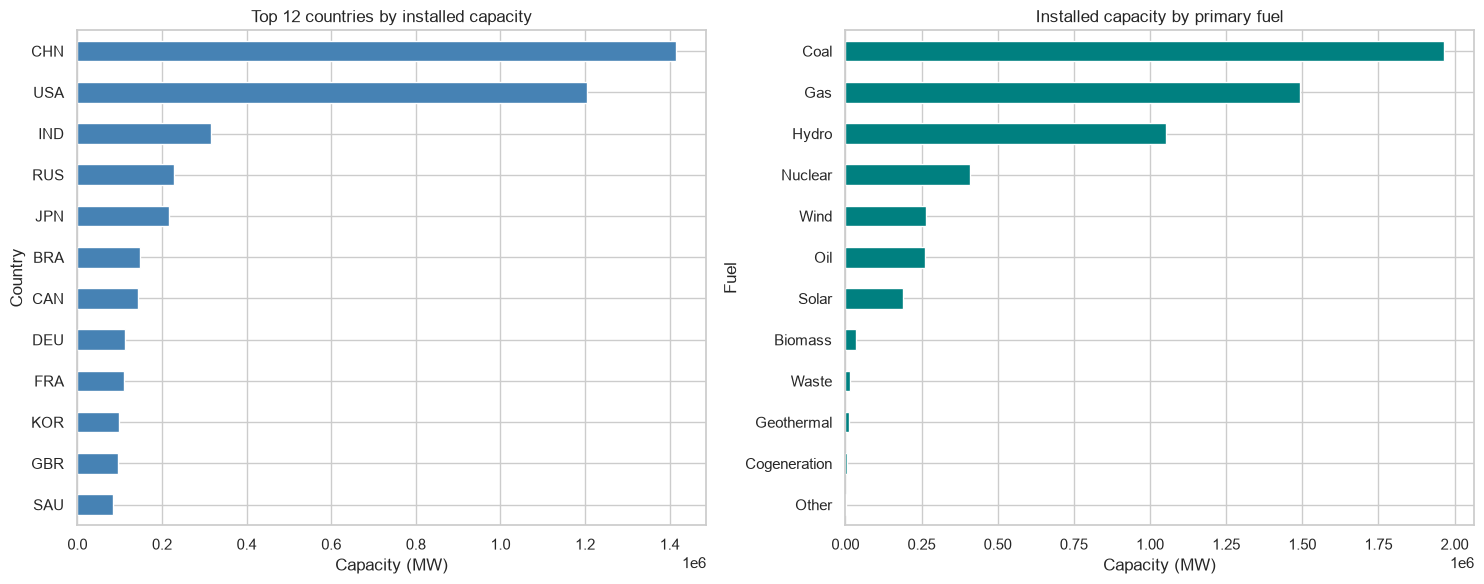

In [4]:
country_summary = df.groupby('country').agg(plants=('capacity_mw','size'), capacity_mw=('capacity_mw','sum')).sort_values('capacity_mw', ascending=False)
fuel_summary = df.groupby('primary_fuel').agg(plants=('capacity_mw','size'), capacity_mw=('capacity_mw','sum'), mean_mw=('capacity_mw','mean'), median_mw=('capacity_mw','median'), std_mw=('capacity_mw','std')).sort_values('capacity_mw', ascending=False)
print('Top countries by installed capacity:')
display(country_summary.head(15))
print('Fuel types by installed capacity:')
display(fuel_summary)
country_summary.to_csv(OUT / 'country_summary.csv')
fuel_summary.to_csv(OUT / 'fuel_summary.csv')
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
country_summary.head(12).sort_values('capacity_mw').plot.barh(y='capacity_mw', ax=ax[0], legend=False, color='steelblue')
ax[0].set(title='Top 12 countries by installed capacity', xlabel='Capacity (MW)', ylabel='Country')
fuel_summary.head(12).sort_values('capacity_mw').plot.barh(y='capacity_mw', ax=ax[1], legend=False, color='teal')
ax[1].set(title='Installed capacity by primary fuel', xlabel='Capacity (MW)', ylabel='Fuel')
savefig('01_country_fuel_capacity.png')

## 3. Fuel-type statistics and hypothesis test

**H₀:** The mean installed capacities of the two most frequent fuel groups are equal. **H₁:** Their means differ. A two-sided Welch t-test is used because variances and sample sizes may differ. Statistical significance does not prove a causal effect of fuel type.

Solar: n=10665, mean=17.66 MW, median=5.80 MW, std=41.94 MW
Hydro: n=7156, mean=147.17 MW, median=20.00 MW, std=549.81 MW
Welch t=-19.8882, p=9.91475e-86
Reject H0 at alpha=0.05


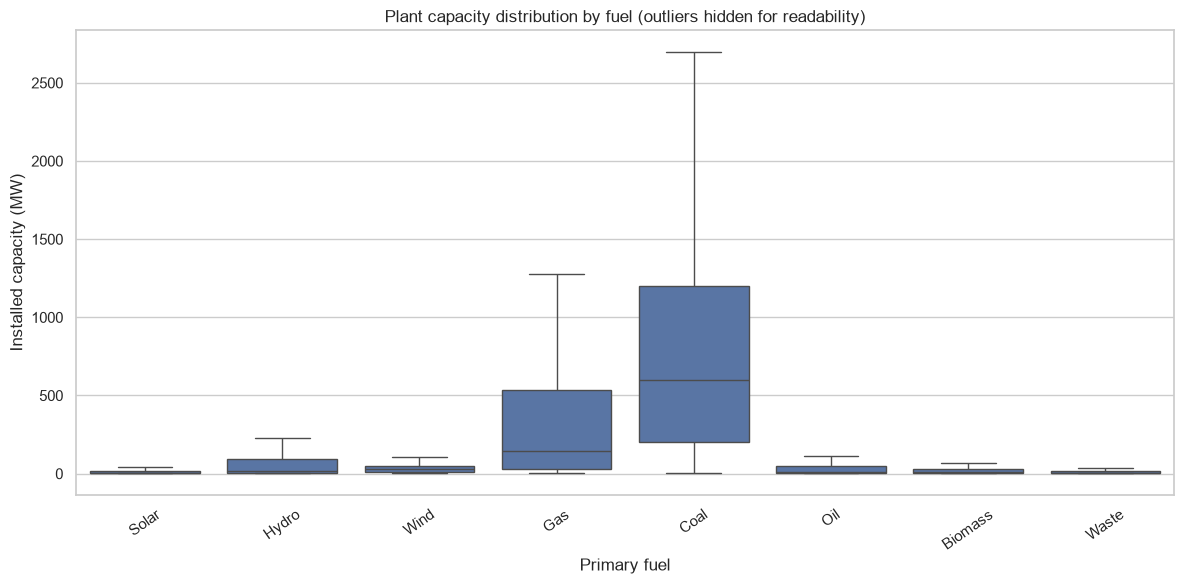

In [5]:
fuel_counts = df['primary_fuel'].value_counts()
eligible = fuel_counts[fuel_counts >= 30].index.tolist()
if len(eligible) >= 2:
    a_name, b_name = eligible[:2]
    a = df.loc[df['primary_fuel'].eq(a_name), 'capacity_mw'].to_numpy(dtype=float)
    b = df.loc[df['primary_fuel'].eq(b_name), 'capacity_mw'].to_numpy(dtype=float)
    test = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
    print(f'{a_name}: n={len(a)}, mean={np.mean(a):,.2f} MW, median={np.median(a):,.2f} MW, std={np.std(a, ddof=1):,.2f} MW')
    print(f'{b_name}: n={len(b)}, mean={np.mean(b):,.2f} MW, median={np.median(b):,.2f} MW, std={np.std(b, ddof=1):,.2f} MW')
    print(f'Welch t={test.statistic:.4f}, p={test.pvalue:.6g}')
    print('Reject H0 at alpha=0.05' if np.isfinite(test.pvalue) and test.pvalue < .05 else 'Do not reject H0 at alpha=0.05')
else:
    print('Insufficient fuel groups with >=30 records for a meaningful comparison.')
selected_fuels = fuel_counts.head(8).index
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df[df['primary_fuel'].isin(selected_fuels)], x='primary_fuel', y='capacity_mw', order=selected_fuels, showfliers=False, ax=ax)
ax.set(title='Plant capacity distribution by fuel (outliers hidden for readability)', xlabel='Primary fuel', ylabel='Installed capacity (MW)')
ax.tick_params(axis='x', rotation=35)
savefig('02_capacity_boxplot.png')

## 4. Historical trends

Commissioning year represents the reported year a plant began operation, **not** its electricity generation in that year. Missing historical dates can bias the apparent trend. Fuel mix below is based on the capacity of plants grouped by their commissioning decade.

Historical coverage: 17,445 of 34,936 records have usable years in 1900–2029.


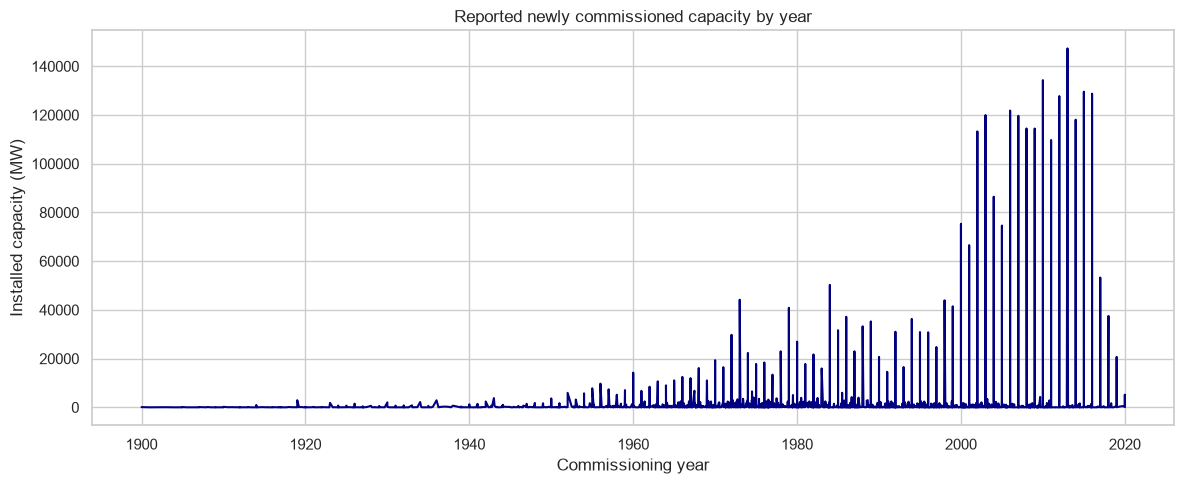

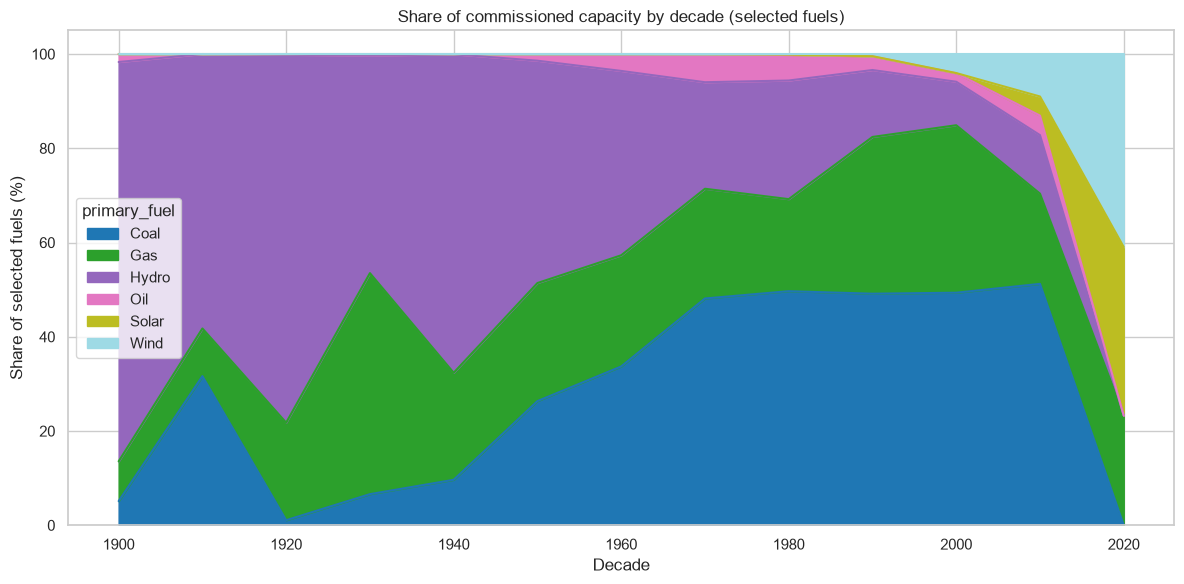

In [6]:
if 'commissioning_year' in df and df['commissioning_year'].notna().any():
    historical = df.dropna(subset=['commissioning_year']).copy()
    historical['decade'] = (historical['commissioning_year'].astype(int) // 10) * 10
    historical = historical[historical['decade'].between(1900, 2020)]
    print(f'Historical coverage: {len(historical):,} of {len(df):,} records have usable years in 1900–2029.')
    yearly = historical.groupby('commissioning_year').agg(plants=('capacity_mw','size'), added_capacity_mw=('capacity_mw','sum'))
    yearly.to_csv(OUT / 'commissioning_year_trends.csv')
    if not yearly.empty:
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.plot(yearly.index, yearly['added_capacity_mw'], color='navy')
        ax.set(title='Reported newly commissioned capacity by year', xlabel='Commissioning year', ylabel='Installed capacity (MW)')
        savefig('03_commissioning_trends.png')
    leading_fuels = fuel_counts.head(6).index
    mix = historical[historical['primary_fuel'].isin(leading_fuels)].pivot_table(index='decade', columns='primary_fuel', values='capacity_mw', aggfunc='sum', fill_value=0)
    if not mix.empty:
        mix.div(mix.sum(axis=1).replace(0,np.nan),axis=0).mul(100).plot(kind='area', stacked=True, figsize=(12, 6), colormap='tab20')
        plt.title('Share of commissioned capacity by decade (selected fuels)')
        plt.xlabel('Decade'); plt.ylabel('Share of selected fuels (%)')
        savefig('04_fuel_mix_decades.png')
else:
    print('Commissioning-year data unavailable; historical analysis skipped.')

## 5. Geographic distribution

Plants with valid coordinates: 34,936


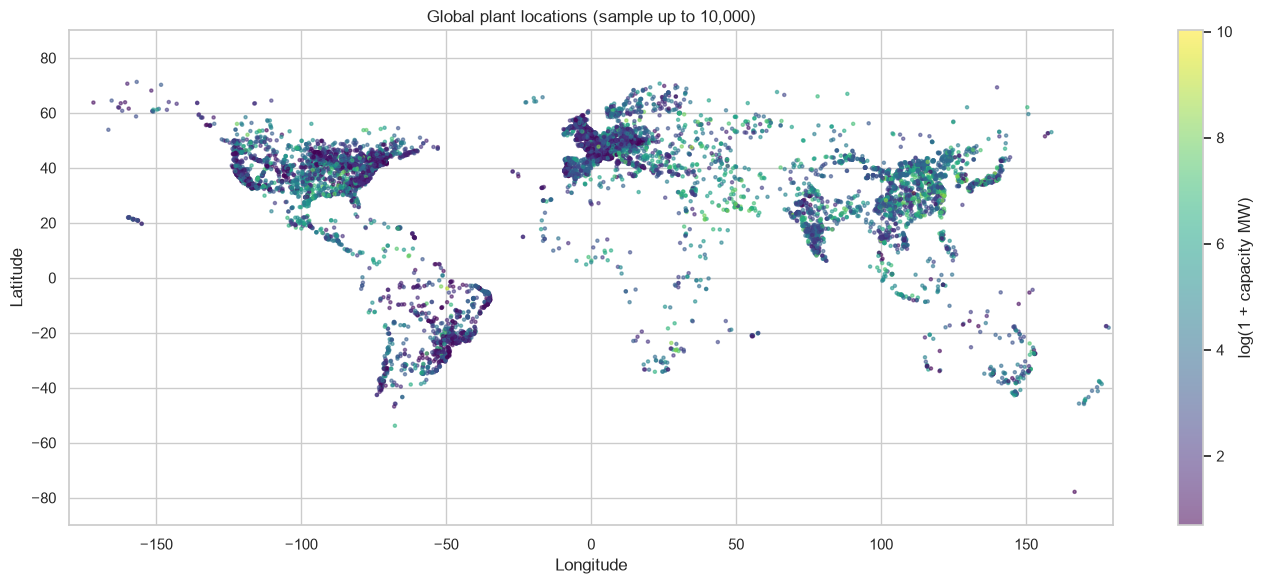

In [7]:
if {'latitude','longitude'}.issubset(df.columns):
    geo = df.dropna(subset=['latitude','longitude']).copy()
    print(f'Plants with valid coordinates: {len(geo):,}')
    if len(geo):
        sample = geo.sample(n=min(10000,len(geo)), random_state=SEED)
        fig, ax = plt.subplots(figsize=(14, 6))
        points = ax.scatter(sample['longitude'],sample['latitude'], c=np.log1p(sample['capacity_mw']), s=5, cmap='viridis', alpha=.55, rasterized=True)
        plt.colorbar(points, ax=ax, label='log(1 + capacity MW)')
        ax.set(title='Global plant locations (sample up to 10,000)',xlabel='Longitude',ylabel='Latitude',xlim=(-180,180),ylim=(-90,90))
        savefig('05_geographic_distribution.png')
else:
    print('Geographic coordinates unavailable; map skipped.')

## 6. Matrix operations, eigenvalues and eigenvectors

We build a numeric feature matrix with capacity and geographic coordinates, standardize it using NumPy, and compute its correlation matrix and eigendecomposition. Eigenvectors identify orthogonal directions of variation; eigenvalues measure how much variance each direction explains. This is descriptive dimensionality reduction, **not** evidence of a causal relationship.

In [ ]:
features = [c for c in ['capacity_mw','latitude','longitude'] if c in df.columns]
matrix_df = df[features].dropna()
if len(features) >= 2 and len(matrix_df) >= 3:
    X = matrix_df.to_numpy(dtype=float)
    mu = np.mean(X, axis=0)
    sd = np.std(X, axis=0, ddof=1)
    nonconstant = sd > 0
    Xz = (X[:, nonconstant] - mu[nonconstant]) / sd[nonconstant]
    kept = np.array(features)[nonconstant].tolist()
    if len(kept) >= 2:
        correlation = np.corrcoef(Xz, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(correlation)
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:,order]
        print('Features:', kept)
        print('Correlation matrix:\n', np.round(correlation, 3))
        print('Eigenvalues:', np.round(eigenvalues, 3))
        print('Explained variance fractions:', np.round(eigenvalues/eigenvalues.sum(), 3))
        print('First eigenvector:', np.round(eigenvectors[:,0], 3))
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(pd.DataFrame(correlation,index=kept,columns=kept), annot=True, cmap='coolwarm', vmin=-1,vmax=1,ax=ax)
        ax.set_title('Correlation of standardized numeric attributes')
        savefig('06_correlation_matrix.png')
    else:
        print('Insufficient nonconstant features for eigendecomposition.')
else:
    print('Insufficient complete numeric records for matrix operations.')

Features: ['capacity_mw', 'latitude', 'longitude']
Correlation matrix:
 [[ 1.    -0.013  0.152]
 [-0.013  1.    -0.068]
 [ 0.152 -0.068  1.   ]]
Eigenvalues: [1.171 0.99  0.838]
Explained variance fractions: [0.39  0.33  0.279]
First eigenvector: [-0.64   0.327 -0.696]


## 7. NumPy–Pandas–Matplotlib integration

In [ ]:
# NumPy Boolean mask filters the Pandas DataFrame, then Matplotlib visualizes the result.
capacities = df['capacity_mw'].to_numpy(dtype=float)
cutoff = np.percentile(capacities, 90)
large_plants = df.loc[capacities >= cutoff].copy()
print(f'90th percentile capacity: {cutoff:,.2f} MW')
print(f'Plants at or above threshold: {len(large_plants):,}')
print('Share of total capacity held by these plants:', f"{100*large_plants['capacity_mw'].sum()/df['capacity_mw'].sum():.1f}%" if df['capacity_mw'].sum()>0 else 'not defined')
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(np.log1p(capacities), bins=40, color='slateblue', edgecolor='white')
ax.set(title='Distribution of log-transformed installed capacity',xlabel='log(1 + capacity MW)',ylabel='Number of plants')
savefig('07_capacity_histogram.png')

## 8. Automatically generated findings and limitations

In [ ]:
total_mw = df['capacity_mw'].sum()
leader_country = country_summary.index[0]
leader_fuel = fuel_summary.index[0]
report = f"""# Global Power Plant Analysis — Executive Summary

- Cleaned dataset: {len(df):,} power plants across {df['country'].nunique():,} countries and {df['primary_fuel'].nunique():,} primary fuel types.
- Total recorded installed capacity: {total_mw:,.1f} MW.
- Largest recorded country by installed capacity: {leader_country} ({country_summary.iloc[0]['capacity_mw']:,.1f} MW).
- Largest recorded primary fuel by installed capacity: {leader_fuel} ({fuel_summary.iloc[0]['capacity_mw']:,.1f} MW).
- Median individual plant capacity: {np.median(capacities):,.2f} MW; mean: {np.mean(capacities):,.2f} MW.

## Methods
NumPy provided vectorized numerical conversion, filtering, percentiles, summary statistics and eigendecomposition. Pandas handled import, missing values, grouping and time-based features. Matplotlib and Seaborn provided comparison, geographic, trend and distribution charts. SciPy provided the Welch two-sample hypothesis test.

## Limitations
The database may omit plants or contain incomplete commissioning years and coordinates. Installed capacity is not realized generation or utilization. Historical charts reflect plants recorded in the dataset rather than all capacity operational at each point in time. Correlations and t-tests describe associations, not causal effects. Geographic plot is a coordinate scatterplot, not a country-boundary choropleth.
"""
print(report)
(OUT/'analysis_report.md').write_text(report,encoding='utf-8')
print('Saved outputs in:', OUT)